# humor-me: the decisions, as plots

**What this is.** The slides first drew their results as Mermaid `xychart` bars, one chart type and one colour per
chart. This notebook redraws them from `reports/metrics/*.json`, in the form that suits each question, with one
colour per mode and per policy across every chart. It runs nothing new from the simulator. The evidence and its
✅/❌ claim checks stay in the section notebooks ([decisions-data](decisions-data.ipynb), [decisions-director](decisions-director.ipynb), [decisions-live](decisions-live.ipynb); index in [decisions.ipynb](decisions.ipynb)); the checks here cover something else: **does each chart
still match its slide, and does every decision have a chart or a stated reason not to?**

**The story in one line.** The six modes rank clearly for an LLM judge, but the best mode depends on the room, so a
director that learns the room beats any fixed mode. It can't follow a room that turns mid-show, and planning didn't fix
that. People rank the modes far more evenly than the judge, and the director choice still holds under their taste.

| Slide | Question | Form | Why this form |
|---|---|---|---|
| 14 | How do the modes rank for the judge? | Lollipop | Distance from 50%, the "average mode" line, is the point |
| 15 | Is one mode best everywhere? | Tile map | Shows the whole 27-room grid at once |
| 16 | Decide per joke or per bit? | Diverging bars | The sign flip is the result |
| 18 | Which director loses the fewest laughs? | Cumulative lines + forest plot | Loss builds up over shows; priors need their CIs |
| 20 | What happens when the room turns? | Dumbbell + gap curve | Before and after for each policy, then when it happens |
| 25 | Did planning fix it? | Line small multiples + dots | Quality per bit shows the decline a single number hides |
| 29 | Can we trust the labels? | Forest plot + unit chart | Samples are small, so the CI matters as much as the value |
| 30 | What else moves upvotes? | Line + scatter | Length is continuous, and the modes sit on the same axes |
| 31 | Do people agree with the judge? | Slope chart + forest plot | Crossing lines show disagreement; the zoom shows the noise |
| 33 | Does the choice survive human taste? | Strip + connected dots | Both tastes, every policy, one axis |
| 15, 17 notes | Is the oracle really the ceiling? | Forest plot + sorted dots | Three policies on one axis, then the gap in each of the 27 rooms |

Slides 15, 16 and 25 are flowcharts rather than `xychart`s. They are here because their boxes carry results that can
be plotted. Vocabulary: [glossary](../docs/wiki/glossary.md). Figures are also saved to
`reports/figures/decision-plot/` for the deck.

In [1]:
import json, os, re, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sim.cache import METRICS, run_or_load

FIGS = ROOT / "reports" / "figures" / "decision-plot"
FIGS.mkdir(parents=True, exist_ok=True)

INK, SLATE, MUTED, GRID, BASE, PAPER = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#ffffff"  # the deck's slides are white
MISSED = "#d03b3b"

# Constant across every chart. Validated with the dataviz palette script: LinUCB, Thompson and Neurotic meet the
# colour-blind floors as a set, because they share a chart on slide 18. Not all eight colours can meet them together,
# so every chart also labels its marks directly and colour never carries identity alone.
MODE = {"neurotic": "#1baf7a", "absurdist": "#6250d6", "cynic": "#e34948",
        "observer": "#eda100", "optimist": "#e87ba4", "wordsmith": "#008300"}
LINE = {"LinUCB": ("#2a78d6", "-"), "Thompson": ("#eb6834", "-"), "ε-greedy": (SLATE, "--"),
        "Oracle": (INK, "-"), "Random": (MUTED, ":"), "Always Neurotic": (MODE["neurotic"], "-"),
        "LinQ, first run": (SLATE, ":"), "LinQ, corrected": (SLATE, "-")}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 11, "figure.dpi": 110, "savefig.dpi": 160,
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": BASE, "axes.labelcolor": SLATE, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 12.5, "axes.titlelocation": "left", "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False,
})


def metric(name):
    return json.loads((METRICS / f"{name}.json").read_text(encoding="utf-8"))["results"]


def show(md_text):
    display(Markdown(md_text))


def check(claim, ok):
    show(f"{'✅' if ok else '❌'} **{claim}**")
    return ok


def slide(name):
    # The numbers typed into a slide's xychart, so a chart can't drift from its slide unnoticed.
    text = (ROOT / "docs" / "slides" / "img" / f"{name}.mmd").read_text(encoding="utf-8")
    labels = re.findall(r'"([^"]+)"', re.search(r"x-axis \[(.+)\]", text).group(1))
    return dict(zip(labels, map(float, re.search(r"bar \[(.+)\]", text).group(1).split(","))))


def check_slide(name, ours, tol):
    typed = slide(name)
    off = {k: (typed[k], round(ours[k], 3)) for k in typed if abs(typed[k] - ours[k]) > tol}
    return check(f"Slide `{name}` matches the metrics ({len(typed)} values, within ±{tol})"
                 + (f"; off: {off}" if off else ""), not off)


def dodge(values, gap):
    # End labels stay in order, never overlap, and stay centred on their marks.
    order = np.argsort(values)
    out, last = np.array(values, dtype=float), -np.inf
    for i in order:
        out[i] = max(values[i], last + gap)
        last = out[i]
    return out - (out - np.array(values)).mean()


def done(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
    plt.show()

## The colour key

**Modes** always wear the same hue, whether as a rank, a best-in-room tile or an always-Neurotic line. **Policies**
do too: LinUCB, the one we chose, is blue, and Thompson is orange. The rest are neutral with a line style, since there
aren't enough safe hues for more. A chart that isn't about one of these things uses neutrals rather than borrow a hue.

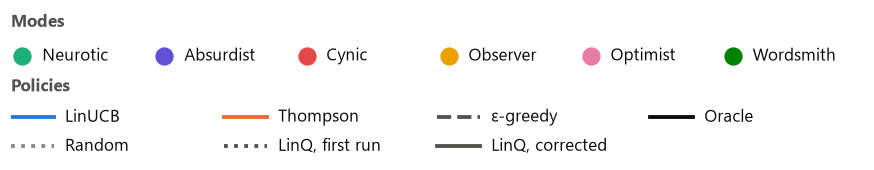

In [2]:
fig, ax = plt.subplots(figsize=(10, 1.75))
ax.axis("off"); ax.set_xlim(0, 6); ax.set_ylim(0, 2)
ax.text(0, 1.75, "Modes", fontweight="bold", color=SLATE)
for i, (m, c) in enumerate(MODE.items()):
    ax.scatter(i + 0.08, 1.3, s=120, color=c)
    ax.text(i + 0.22, 1.3, m.capitalize(), va="center")
ax.text(0, 0.75, "Policies", fontweight="bold", color=SLATE)
items = [k for k in LINE if k != "Always Neurotic"]
for i, k in enumerate(items):
    c, ls = LINE[k]
    col, row = i % 4, i // 4
    x, y = col * 1.5, 0.35 - row * 0.45
    ax.plot([x, x + 0.3], [y, y], color=c, ls=ls, lw=2.5)
    ax.text(x + 0.38, y, k, va="center")
ax.set_ylim(-0.3, 2)
done(fig, "00-colour-key")

## 1. Where it starts: the judge has a clear favourite (slide 14)

**Context.** The robot has one identity and six attitudes, the modes from HumorGen. HumorGen's LLM judge (Llama-3.3-70B)
compared jokes in pairs, and these are its win rates from Table 4. They are the paper's numbers, not ours.

**Why a lollipop.** A win rate of 50% means an average mode, so the length of each stem from that line is the message.
A bar from an arbitrary axis floor would show less.

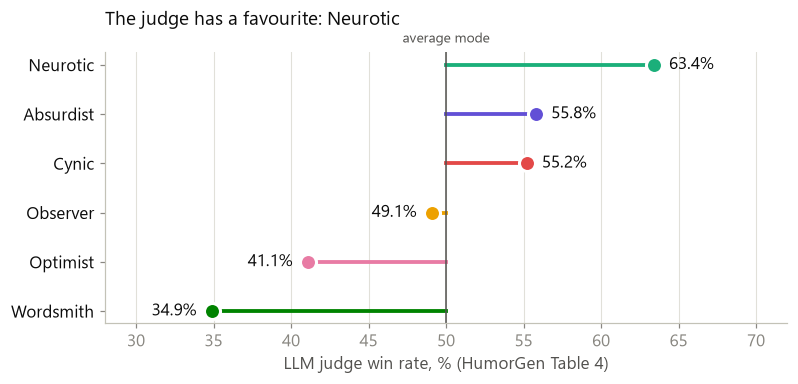

✅ **Slide `14-six-modes-one-robot` matches the metrics (6 values, within ±0.05)**

True

In [3]:
rank = metric("mode_ranking")
modes = rank["modes"]
judge = dict(zip(modes, np.array(rank["judge"]) * 100))

fig, ax = plt.subplots(figsize=(8, 3.2))
for y, m in enumerate(reversed(modes)):
    ax.plot([50, judge[m]], [y, y], color=MODE[m], lw=2.5)
    ax.scatter(judge[m], y, s=110, color=MODE[m], zorder=3, edgecolor=PAPER, linewidth=2)
    ax.annotate(f"{judge[m]:.1f}%", (judge[m], y), xytext=(10 if judge[m] > 50 else -10, 0), textcoords="offset points",
                va="center", ha="left" if judge[m] > 50 else "right")
ax.axvline(50, color=SLATE, lw=1)
ax.annotate("average mode", (50, 5.45), ha="center", color=SLATE, fontsize=9, annotation_clip=False)
ax.set_yticks(range(6), [m.capitalize() for m in reversed(modes)], color=INK)
ax.set_xlim(28, 72); ax.set_xlabel("LLM judge win rate, % (HumorGen Table 4)"); ax.grid(axis="y", visible=False)
ax.set_title("The judge has a favourite: Neurotic", pad=18)
done(fig, "14-judge-modes")

check_slide("14-six-modes-one-robot", {m.capitalize(): v for m, v in judge.items()}, 0.05)

**What it sets up.** This gives us the obvious baseline to beat: always be Neurotic. But one ranking assumes every
room wants the same thing. Next we check that against the simulator's rooms.

## 2. Is one mode best everywhere? (slide 15)

**Context.** The simulated room is venue × energy × age, which makes 27 kinds of room. Each tile below shows the fixed
mode that earns the most laughs in that room.

**Why a tile map.** The question is about the whole grid, and the colours are the same mode colours as above, so
Neurotic's scarcity can be seen at a glance.

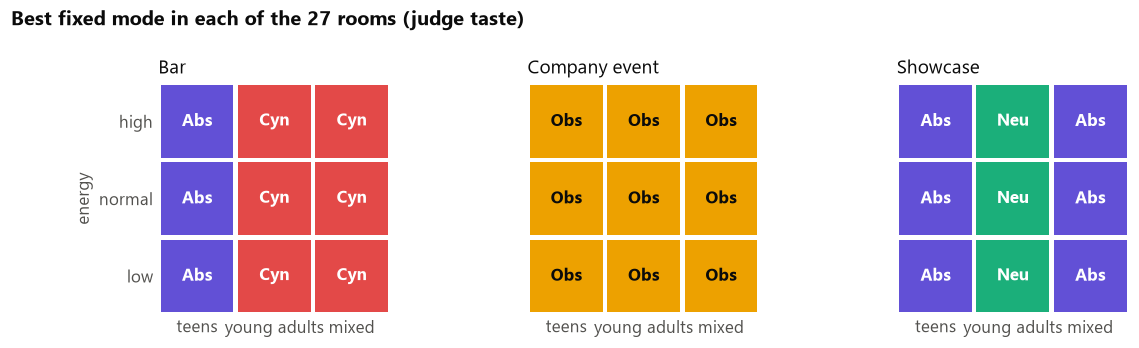

neurotic: 3 rooms · absurdist: 9 rooms · cynic: 6 rooms · observer: 9 rooms · optimist: 0 rooms · wordsmith: 0 rooms

✅ **Neurotic tops the judge's ranking yet is best in only 3 of 27 rooms**

✅ **No single mode is best in more than a third of the rooms**

True

In [4]:
env = metric("sim_env")
best = env["best_mode_by_context"]
venues, energies, ages = ["bar", "company_event", "showcase"], ["high", "normal", "low"], ["teens", "young_adults", "mixed"]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, v in zip(axes, venues):
    for r, e in enumerate(energies):
        for c, a in enumerate(ages):
            m = best[f"{v}/{e}/{a}"]
            ax.add_patch(plt.Rectangle((c + .03, 2 - r + .03), .94, .94, color=MODE[m], lw=0))
            ax.text(c + .5, 2 - r + .5, m[:3].capitalize(), ha="center", va="center", fontweight="bold",
                    color=INK if m == "observer" else "white")
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.grid(False); ax.set_aspect("equal")
    ax.spines[["left", "bottom"]].set_visible(False); ax.tick_params(length=0)
    ax.set_xticks([.5, 1.5, 2.5], ["teens", "young adults", "mixed"], color=SLATE)
    ax.set_yticks([2.5, 1.5, .5], energies, color=SLATE)
    ax.set_title(v.replace("_", " ").capitalize())
axes[0].set_ylabel("energy")
fig.suptitle("Best fixed mode in each of the 27 rooms (judge taste)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
done(fig, "15-best-mode-by-room")

from collections import Counter
wins = Counter(best.values())
show(" · ".join(f"{m}: {wins.get(m, 0)} rooms" for m in MODE))
check("Neurotic tops the judge's ranking yet is best in only 3 of 27 rooms", wins["neurotic"] == 3)
check("No single mode is best in more than a third of the rooms", max(wins.values()) <= 9)

**What it shows.** The judge's favourite is best in only 3 of 27 rooms, and optimist and wordsmith are best in none.
So a director that reads the room has something to win.

**What is made up.** The venue and age offsets come from `sim/audience.yaml`, not from audiences, so this map shows the
simulator's assumption rather than a fact about comedy. Energy never changes the winner because `audience.yaml` adds it
equally to every mode, which leaves 9 effectively different rooms.

## 3. How often should the director decide? (slide 16)

**Context.** The first version picked a mode for every joke, and random beat every fixed mode. That was a flag: if
rotating blindly wins, the sim is rewarding rotation, not fit. Fatigue outweighed fit at that granularity. A comedian
commits to an attitude for a whole bit, so we tried deciding per bit.

**Why diverging bars.** The result is a sign flip around zero. Above zero, fitting the room beats random; below it,
rotation wins. Each venue wears the colour of its best fixed mode, and hatching marks the rejected per-joke setup.

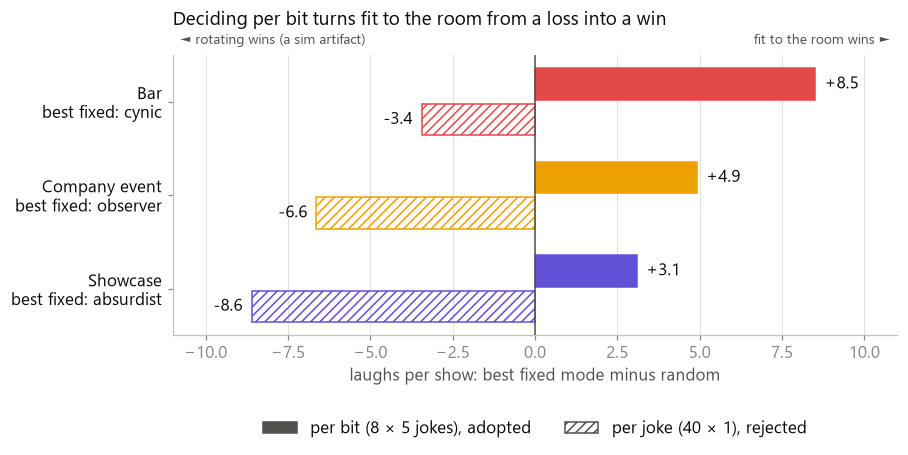

✅ **Per joke: random beats the best fixed mode in every venue**

✅ **Per bit: fit wins by 3 to 9 laughs (3.1 to 8.5)**

True

In [5]:
per_joke = metric("sim_env_per_joke")["venues"]
per_bit = env["venues"]

fig, ax = plt.subplots(figsize=(8.5, 3.3))
for i, (j, b) in enumerate(zip(reversed(per_joke), reversed(per_bit))):
    c = MODE[b["best_fixed_mode"]]
    for off, r, solid in ((.19, b, True), (-.19, j, False)):
        d = r["best_fixed"] - r["random"]
        ax.barh(i + off, d, height=.34, color=c if solid else "none", edgecolor=c, hatch=None if solid else "////", lw=1)
        ax.annotate(f"{d:+.1f}", (d, i + off), xytext=(6 if d > 0 else -6, 0), textcoords="offset points",
                    va="center", ha="left" if d > 0 else "right")
ax.axvline(0, color=SLATE, lw=1)
ax.set_yticks(range(3), [f"{b['venue'].replace('_', ' ').capitalize()}\nbest fixed: {b['best_fixed_mode']}" for b in reversed(per_bit)], color=INK)
ax.set_xlim(-11, 11); ax.set_xlabel("laughs per show: best fixed mode minus random"); ax.grid(axis="y", visible=False)
ax.text(-10.8, 2.62, "◄ rotating wins (a sim artifact)", color=SLATE, fontsize=9)
ax.text(10.8, 2.62, "fit to the room wins ►", color=SLATE, fontsize=9, ha="right")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=SLATE, label="per bit (8 × 5 jokes), adopted"),
                   plt.Rectangle((0, 0), 1, 1, facecolor="none", edgecolor=SLATE, hatch="////", label="per joke (40 × 1), rejected")],
          loc="lower center", bbox_to_anchor=(.5, -.42), ncol=2)
ax.set_title("Deciding per bit turns fit to the room from a loss into a win", pad=20)
done(fig, "16-per-joke-vs-per-bit")

gaps = [b["best_fixed"] - b["random"] for b in per_bit]
check(f"Per joke: random beats the best fixed mode in every venue", all(j["best_fixed"] < j["random"] for j in per_joke))
check(f"Per bit: fit wins by 3 to 9 laughs ({min(gaps):.1f} to {max(gaps):.1f})", 3 <= min(gaps) and max(gaps) <= 9)

**What it decided.** The director picks a mode per bit, 8 decisions a show. The cost is learning speed: telling the top
two modes apart takes 14 to 177 shows, so learning has to span many shows. That calls for a learner that shares what it
learns between rooms.

## 4. Which director? (slide 18)

**Context.** We compared three learners across a career of 300 shows, against two baselines. *Laughs lost* is the
running gap to the oracle, so a flatter line means a director that has stopped losing. ε-greedy keeps a separate table
per room; LinUCB and Thompson share one model across rooms through features. We also started each from three priors,
including one from the LLM judge and a deliberately wrong one.

**Why these forms.** Loss builds up over time, so lines show what a final bar can't: when each policy stops bleeding.
The first-20-shows panel is there because **the demo has about 5 shows, not 300**. The priors are a comparison of
near-ties, so the forest plot's CIs are the whole point.

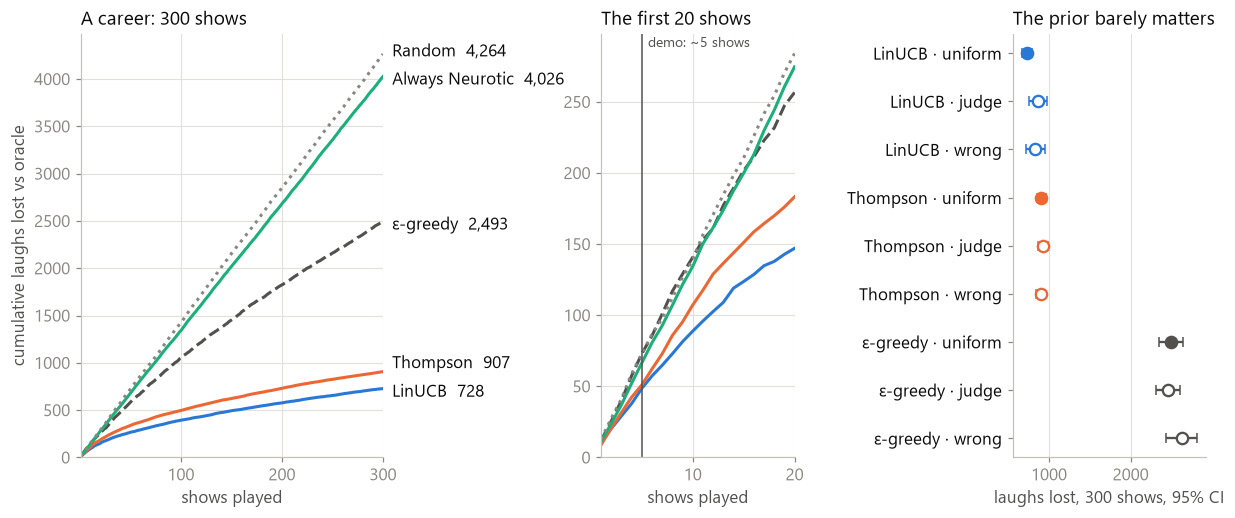

✅ **Slide `18-sharing-beats-the-starting-guess` matches the metrics (5 values, within ±0.5)**

✅ **Sharing matters: ε-greedy loses 3.4× LinUCB**

✅ **LinUCB's three priors have overlapping CIs**

**At the horizon the demo uses.** Laughs lost after 5 shows: LinUCB 49, Thompson 51, ε-greedy 73, Always Neurotic 66, Random 73.

Laughs per show over the first 10 shows, 95% CI: LinUCB 44.7 ± 1.8, Thompson 43.5 ± 2.4, ε-greedy 40.3 ± 2.2, Always Neurotic 41.7 ± 2.1, Random 40.5 ± 2.1. Oracle: 50.8.

In [6]:
pol = metric("policies")
curves = {"LinUCB": "LinUCB | uniform", "Thompson": "Thompson (LinTS) | uniform", "ε-greedy": "ε-greedy | uniform",
          "Always Neurotic": "fixed neurotic", "Random": "random"}

fig, (a, b, c) = plt.subplots(1, 3, figsize=(13.2, 5), gridspec_kw={"width_ratios": [1.25, .8, .8]})
ends = [pol[k]["lost_curve"][-1] for k in curves.values()]
for (name, key), pos in zip(curves.items(), dodge(ends, 300)):
    col, ls = LINE[name]
    y = pol[key]["lost_curve"]
    a.plot(range(1, len(y) + 1), y, color=col, ls=ls)
    a.annotate(f"{name}  {y[-1]:,.0f}", (len(y), pos), xytext=(6, 0), textcoords="offset points", va="center", annotation_clip=False)
    b.plot(range(1, 21), y[:20], color=col, ls=ls)
a.set_xlim(1, 300); a.set_ylim(0); a.set_xlabel("shows played"); a.set_ylabel("cumulative laughs lost vs oracle")
a.set_title("A career: 300 shows")
b.axvline(5, color=SLATE, lw=1); b.annotate("demo: ~5 shows", (5, b.get_ylim()[1]), xytext=(4, -2), textcoords="offset points", va="top", color=SLATE, fontsize=9)
b.set_xlim(1, 20); b.set_ylim(0); b.set_xlabel("shows played"); b.set_title("The first 20 shows")

rows = []
for algo, key in (("LinUCB", "LinUCB"), ("Thompson", "Thompson (LinTS)"), ("ε-greedy", "ε-greedy")):
    rows += [(algo, p, f"{key} | {k}") for k, p in (("uniform", "uniform"), ("humorgen", "judge"), ("wrong", "wrong"))]
for i, (algo, p, key) in enumerate(reversed(rows)):
    m, h = pol[key]["lost_total"]
    filled = p == "uniform"
    c.errorbar(m, i, xerr=h, color=LINE[algo][0], lw=1.5, capsize=3, zorder=2)
    c.scatter(m, i, s=55, color=LINE[algo][0] if filled else PAPER, edgecolor=LINE[algo][0], lw=1.5, zorder=3)
c.set_yticks(range(len(rows)), [f"{a_} · {p}" for a_, p, _ in reversed(rows)], color=INK)
c.grid(axis="y", visible=False); c.set_xlabel("laughs lost, 300 shows, 95% CI"); c.set_title("The prior barely matters")
fig.subplots_adjust(wspace=.95)
done(fig, "18-laughs-lost")

uni = {k: pol[v]["lost_total"][0] for k, v in curves.items()}
check_slide("18-sharing-beats-the-starting-guess",
            {"LinUCB": uni["LinUCB"], "Thompson": uni["Thompson"], "ε-greedy": uni["ε-greedy"],
             "Always-Neurotic": uni["Always Neurotic"], "Random": uni["Random"]}, 0.5)
check(f"Sharing matters: ε-greedy loses {uni['ε-greedy'] / uni['LinUCB']:.1f}× LinUCB", uni["ε-greedy"] / uni["LinUCB"] >= 2)

lins = [pol[f"LinUCB | {p}"]["lost_total"] for p in ("humorgen", "uniform", "wrong")]
check("LinUCB's three priors have overlapping CIs", max(m - h for m, h in lins) <= min(m + h for m, h in lins))

at5 = {k: pol[v]["lost_curve"][4] for k, v in curves.items()}
cold = {k: pol[v]["cold"] for k, v in curves.items()}
show("**At the horizon the demo uses.** Laughs lost after 5 shows: " + ", ".join(f"{k} {v:.0f}" for k, v in at5.items())
     + ".\n\nLaughs per show over the first 10 shows, 95% CI: "
     + ", ".join(f"{k} {m:.1f} ± {h:.1f}" for k, (m, h) in cold.items()) + f". Oracle: {pol['oracle']['cold'][0]:.1f}.")

**What it decided.** LinUCB with a uniform prior: sharing across rooms cuts the loss by 3.4 times against ε-greedy, and
the prior stays out of the way, which also keeps the judge's taste out of the agent. Thompson is close, so this isn't a
claim that LinUCB is the only good learner.

**The caveat the career panel hides.** The 300-show gap is what got LinUCB chosen, but the demo lives in the left edge
of the middle panel, where LinUCB is only a couple of dozen laughs ahead of Random in total. Read the 5-show numbers
above before claiming the demo itself will show the learning. Everything here also rests on the made-up offsets in `audience.yaml`; slide 33
replaces the base taste, but not those offsets.

## 5. Then we tried to break it (slide 20)

**Context.** A bandit assumes each room stays the same. But a real room turns. So halfway through a set, unannounced,
the simulator changes the room's taste, and we measure the second half against an oracle that knows about the change.

**Why a dumbbell, then a curve.** The dumbbell shows the before and after per policy; the distance is the damage. It
also gives the slide's three numbers their missing context: Random steady is low too. The curve shows that the drop
happens at once and doesn't recover.

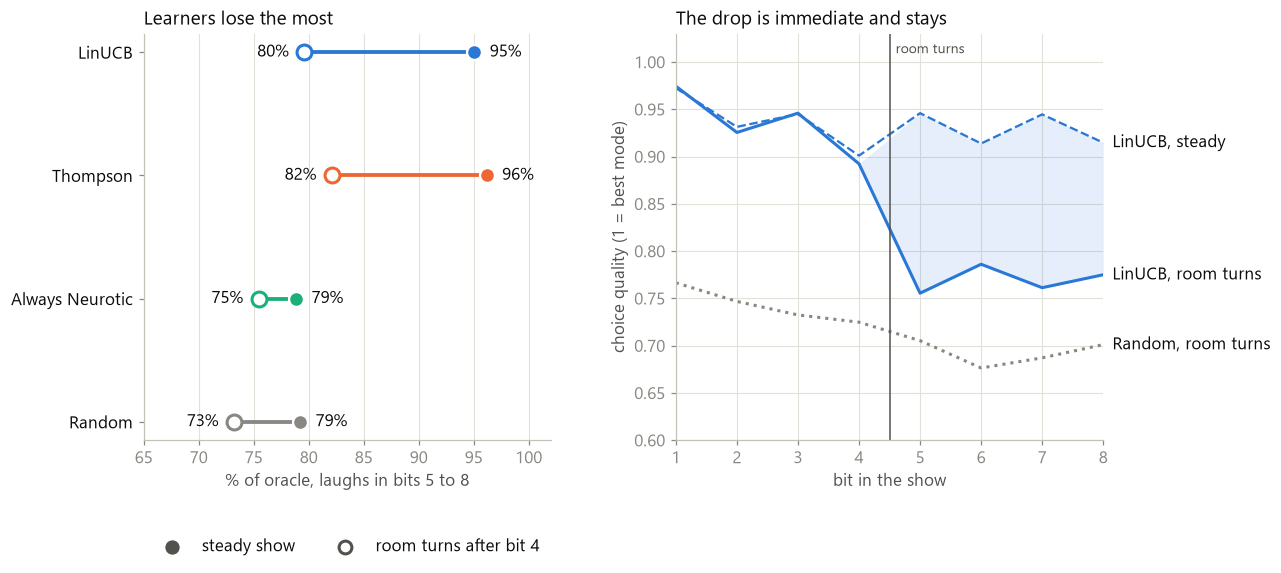

✅ **Slide `20-when-the-room-turns` matches the metrics (3 values, within ±0.5)**

✅ **LinUCB's average choice quality in bits 5 to 8 stays below 0.8 after a turn**

np.True_

In [7]:
sh = metric("shift")
share = lambda n, kind: 100 * sh[n][kind]["post"][0] / sh["oracle"][kind]["post"][0]
rows = [("LinUCB", "LinUCB"), ("Thompson", "LinTS"), ("Always Neurotic", "fixed neurotic"), ("Random", "random")]

fig, (a, b) = plt.subplots(1, 2, figsize=(12.2, 4.8), gridspec_kw={"width_ratios": [1, 1.05]})
for y, (name, key) in enumerate(reversed(rows)):
    col = LINE[name][0]
    s, t = share(key, "steady"), share(key, "shifted")
    a.plot([t, s], [y, y], color=col, lw=2.5, zorder=1)
    a.scatter(s, y, s=95, color=col, edgecolor=PAPER, lw=1.5, zorder=3)
    a.scatter(t, y, s=95, color=PAPER, edgecolor=col, lw=2, zorder=3)
    a.annotate(f"{s:.0f}%", (s, y), xytext=(10, 0), textcoords="offset points", va="center")
    a.annotate(f"{t:.0f}%", (t, y), xytext=(-10, 0), textcoords="offset points", va="center", ha="right")
a.set_yticks(range(4), [n for n, _ in reversed(rows)], color=INK); a.grid(axis="y", visible=False); a.set_xlim(65, 102)
a.set_xlabel("% of oracle, laughs in bits 5 to 8"); a.set_title("Learners lose the most")
a.scatter([], [], s=70, color=SLATE, label="steady show"); a.scatter([], [], s=70, color=PAPER, edgecolor=SLATE, lw=2, label="room turns after bit 4")
a.legend(loc="lower center", bbox_to_anchor=(.5, -.32), ncol=2)

r8 = metric("shift_set_length")["8"]
bits = np.arange(1, 9)
steady, shifted = r8["steady_curve"]["LinUCB"], r8["curve"]["LinUCB"]
blue = LINE["LinUCB"][0]
b.fill_between(bits, shifted, steady, where=bits >= 5, color=blue, alpha=.12, lw=0, interpolate=True)
b.plot(bits, steady, color=blue, ls="--", lw=1.5); b.plot(bits, shifted, color=blue)
b.plot(bits, r8["curve"]["random"], color=MUTED, ls=":")
b.axvline(4.5, color=SLATE, lw=1); b.annotate("room turns", (4.5, 1.02), xytext=(4, 0), textcoords="offset points", color=SLATE, fontsize=9, va="top")
for y, t in ((steady[-1], "LinUCB, steady"), (shifted[-1], "LinUCB, room turns"), (r8["curve"]["random"][-1], "Random, room turns")):
    b.annotate(t, (8, y), xytext=(6, 0), textcoords="offset points", va="center", annotation_clip=False)
b.set_xlim(1, 8); b.set_ylim(.6, 1.03); b.set_xlabel("bit in the show"); b.set_ylabel("choice quality (1 = best mode)")
b.set_title("The drop is immediate and stays")
fig.subplots_adjust(wspace=.3, right=.84)
done(fig, "20-when-the-room-turns")

check_slide("20-when-the-room-turns", {"LinUCB, steady show": share("LinUCB", "steady"), "LinUCB, shifted show": share("LinUCB", "shifted"),
                                        "Random, shifted show": share("random", "shifted")}, 0.5)
check("LinUCB's average choice quality in bits 5 to 8 stays below 0.8 after a turn", np.mean(shifted[4:]) < .8)

**What it shows.** LinUCB drops by about 15 points and Random by about 6, because Random had less to lose. LinUCB's estimates
average hundreds of shows, so one bombed bit barely moves them. It reads rooms, not a room turning. A set of 8 bits isn't
to blame either: lengths up to 52 bits leave the same gap (slide 21, Exp 6).

## 6. Could planning fix it? (slide 25)

**Context.** Steps A and B tried remembering tonight and failed the bar. Step C has the director plan across the show
with linear Q-learning, so it could value trying something new. The first run locked on to one mode. We traced that
to a scale error: modes started at one bit's reward, but Q-values estimate the rest of the show. One corrected run was
approved in advance. A review then found a bug in it, so it was fixed and re-run once; the chart shows
the fixed run.

**Why small multiples.** The slide's flowchart gives 0.95 to 0.72, but that decline needs to be seen against LinUCB, and
on steady shows, where nothing changed. The dots on the right check the diagnosis itself: did correcting the scale stop
the repeats?

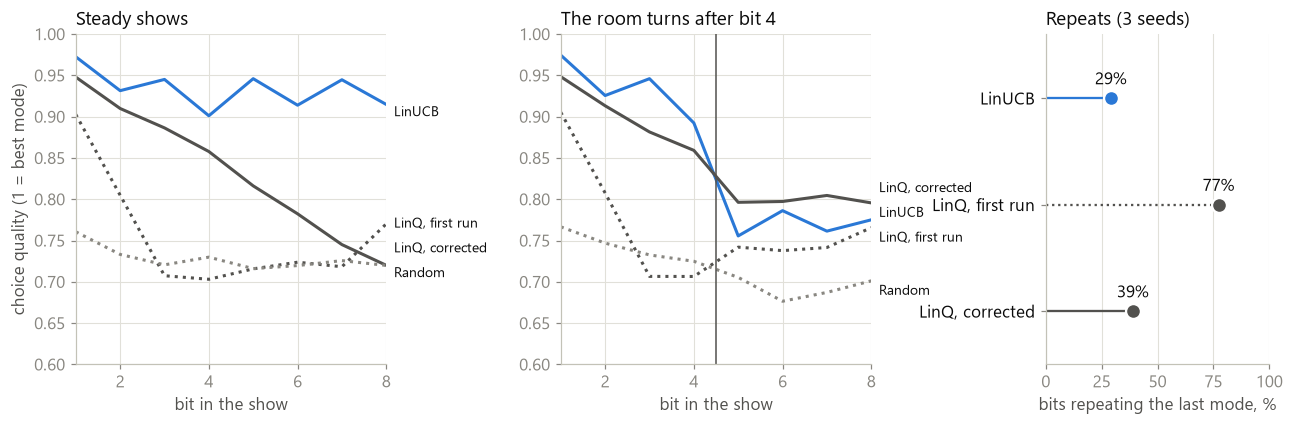

✅ **The fix stopped the lock-on: repeats 77% → 39%**

✅ **Quality still falls with no turn: 0.95 → 0.72**

✅ **LinUCB ends steady shows above the corrected run, whose gain after a turn (+0.029) misses the +0.05 bar**

np.True_

In [8]:
c1, c1b = metric("show_state_c1")["8"], metric("show_state_c1b")["8"]
be1, be2 = metric("show_state_c1_behaviour"), metric("show_state_c1b_behaviour")
series = {"steady_curve": "Steady shows", "curve": "The room turns after bit 4"}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw={"width_ratios": [1, 1, .72]})
for ax, (key, title) in zip(axes, series.items()):
    lines = {"LinUCB": c1[key]["LinUCB"], "LinQ, first run": c1[key]["LinQ"], "LinQ, corrected": c1b[key]["LinQ refit"], "Random": c1[key]["random"]}
    for (n, y), pos in zip(lines.items(), dodge([v[-1] for v in lines.values()], .03)):
        ax.plot(bits, y, color=LINE[n][0], ls=LINE[n][1])
        ax.annotate(n, (8, pos), xytext=(5, 0), textcoords="offset points", va="center", annotation_clip=False, fontsize=9)
    ax.set_xlim(1, 8); ax.set_ylim(.6, 1); ax.set_xlabel("bit in the show"); ax.set_title(title)
axes[0].set_ylabel("choice quality (1 = best mode)")
axes[1].axvline(4.5, color=SLATE, lw=1)
axes[1].sharey(axes[0])

rep = [("LinUCB", be1["LinUCB"]["repeat_rate"]), ("LinQ, first run", be1["LinQ"]["repeat_rate"]), ("LinQ, corrected", be2["LinQ refit"]["repeat_rate"])]
ax = axes[2]
for y, (n, v) in enumerate(reversed(rep)):
    col, ls = LINE[n]
    ax.plot([0, v * 100], [y, y], color=col, ls=ls, lw=1.5); ax.scatter(v * 100, y, s=95, color=col, zorder=3, edgecolor=PAPER, lw=1.5)
    ax.annotate(f"{v:.0%}", (v * 100, y), xytext=(0, 9), textcoords="offset points", ha="center")
ax.set_yticks(range(3), [n for n, _ in reversed(rep)], color=INK); ax.set_xlim(0, 100); ax.set_ylim(-.5, 2.6)
ax.grid(axis="y", visible=False); ax.set_xlabel("bits repeating the last mode, %"); ax.set_title("Repeats (3 seeds)")
fig.subplots_adjust(wspace=.62)
done(fig, "25-step-c-planning")

fall = c1b["steady_curve"]["LinQ refit"]
check(f"The fix stopped the lock-on: repeats {be1['LinQ']['repeat_rate']:.0%} → {be2['LinQ refit']['repeat_rate']:.0%}",
      be1["LinQ"]["repeat_rate"] > .7 and be2["LinQ refit"]["repeat_rate"] < .4)
check(f"Quality still falls with no turn: {fall[0]:.2f} → {fall[-1]:.2f}", round(fall[0], 2) == .95 and round(fall[-1], 2) == .72)
after = lambda y: np.mean(y[4:])
gain = after(c1b["curve"]["LinQ refit"]) - after(c1["curve"]["LinUCB"])
check(f"LinUCB ends steady shows above the corrected run, whose gain after a turn ({gain:+.3f}) misses the +0.05 bar",
      c1["steady_curve"]["LinUCB"][-1] > fall[-1] and round(gain, 3) == .029 and gain < .05)

**What it decided.** The diagnosis held, since repeats fell from 77% to 39%, but the corrected director gets worse
through every show even when nothing changes. It reads a turn slightly better than LinUCB (+0.03 after the shift at 8
bits, with overlapping CIs) and pays for that in steady shows (−0.16). The likely causes were measured once and not tested
separately. Every run failed the bar fixed beforehand, so C1 is a negative result and the demo keeps LinUCB. It says a linear model on these inputs didn't beat LinUCB, not that
planning can't work. The repeat rates carry no CI, as they come from 3 seeds; the pass/fail decision itself is in
[decisions-director.ipynb](decisions-director.ipynb), Exp 14 and 15.

That closes the simulator's question for now. All of it rests on a judge's taste, though, so we turn to real people.

## 7. Before using upvotes: can we trust the labels? (slide 29)

**Context.** To compare people with the judge, we labelled 90k rJokes with a mode using Qwen2.5-7B on Explorer. Before
using those labels, we hand-checked 105 of them. **"Judge" here means our Qwen labeler, not HumorGen's Llama judge.**

**Why a forest plot and a unit chart.** With only 7 to 14 judged jokes per mode, a precision of 100% could be as low as
65%, and the mode comparison hinges on that width. A bar would hide it. Safety is a count of individual misses, so each
joke gets its own mark.

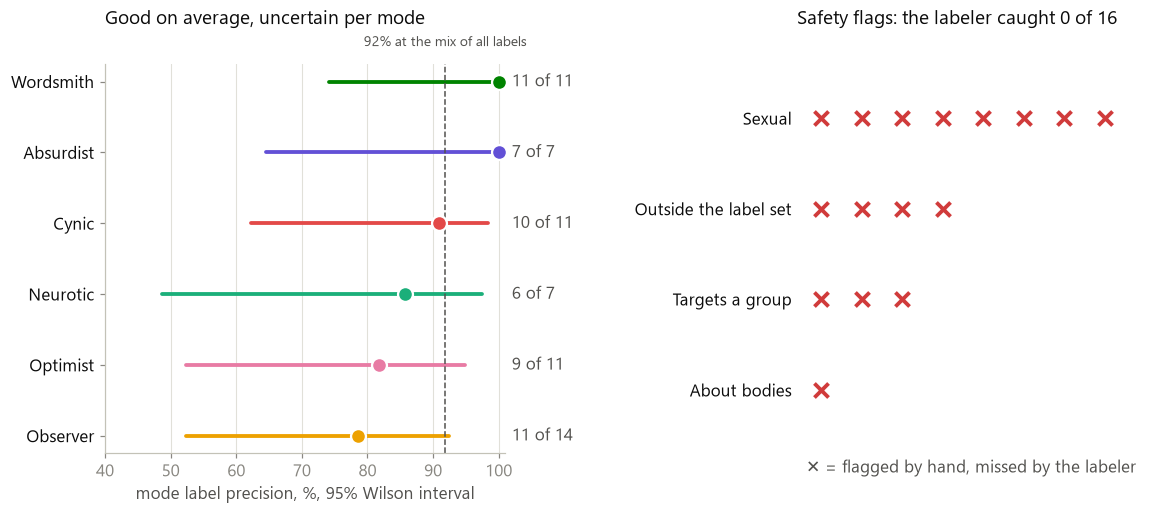

✅ **Slide `29-the-hand-check` matches the metrics (6 values, within ±0.5)**

✅ **Weighted precision is about 92% (91.9%); raw is 89%**

✅ **The Qwen labeler caught none of the 16 human-flagged jokes**

True

In [9]:
hc = metric("hand_check")
pm = {m: s for m, s in hc["per_mode"].items() if m != "none"}
ranked = sorted(pm, key=lambda m: (pm[m]["precision"], pm[m]["y"] + pm[m]["n"]))

fig, (a, b) = plt.subplots(1, 2, figsize=(12.2, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
for y, m in enumerate(ranked):
    s = pm[m]
    p, (lo, hi) = s["precision"] * 100, (s["ci"][0] * 100, s["ci"][1] * 100)
    a.plot([lo, hi], [y, y], color=MODE[m], lw=2.5, solid_capstyle="round")
    a.scatter(p, y, s=95, color=MODE[m], zorder=3, edgecolor=PAPER, lw=1.5)
    a.annotate(f"{s['y']} of {s['y'] + s['n']}", (102, y), va="center", color=SLATE, annotation_clip=False)
w = hc["weighted_precision"] * 100
a.axvline(w, color=SLATE, lw=1, ls="--")
a.annotate(f"{w:.0f}% at the mix of all labels", (w, 5.5), ha="center", color=SLATE, fontsize=9, annotation_clip=False)
a.set_yticks(range(6), [m.capitalize() for m in ranked], color=INK); a.grid(axis="y", visible=False)
a.set_xlim(40, 101); a.set_xlabel("mode label precision, %, 95% Wilson interval")
a.set_title("Good on average, uncertain per mode", pad=26)

flags = sorted(hc["safety"]["by_flag"].items(), key=lambda kv: -kv[1]["human"])
names = {"sexual": "Sexual", "outside schema": "Outside the label set", "targets_group": "Targets a group", "about_bodies": "About bodies"}
for y, (f, v) in enumerate(reversed(flags)):
    for i in range(v["human"]):
        b.scatter(i, y, marker="x", s=85, color=MISSED, lw=2.5)
b.set_yticks(range(len(flags)), [names[f] for f, _ in reversed(flags)], color=INK)
b.set_xticks([]); b.grid(False); b.spines[["left", "bottom"]].set_visible(False); b.tick_params(length=0)
b.set_xlim(-.6, 8); b.set_ylim(-.7, 3.6)
s = hc["safety"]
b.set_xlabel("✕ = flagged by hand, missed by the labeler")
b.set_title(f"Safety flags: the labeler caught {s['judge_flagged_any_of_those']} of {s['human_flagged']}", pad=26)
fig.subplots_adjust(wspace=.78)
done(fig, "29-hand-check")

check_slide("29-the-hand-check", {m.capitalize(): pm[m]["precision"] * 100 for m in pm}, 0.5)
check(f"Weighted precision is about 92% ({hc['weighted_precision']:.1%}); raw is {hc['sample_precision']:.0%}", abs(hc["weighted_precision"] - .92) < .005)
check("The Qwen labeler caught none of the 16 human-flagged jokes", s["judge_flagged_any_of_those"] == 0 and s["human_flagged"] == 16)

**What it decided.** Mode labels are good enough for statistics across thousands of jokes, though about 8% are wrong,
and the misses lean toward puns filed elsewhere. Safety labels aren't usable: rJokes is for mode statistics only, never
joke material, and safety stays a hard filter in the live loop. Four of the 16 had flags outside the set the labeler was
asked about, so 12 is the fairer count of what it could match by name; it flagged none of the 16 with anything at all.

## 8. A confound first: length (slide 30)

**Context.** Modes differ in length, with wordsmith jokes the shortest. If longer jokes get more upvotes regardless of
the attitude, raw mode averages are partly measuring length.

**Why a line with mode dots.** Length is continuous, so a line shows the trend, which the slide's four bins hide: they
skip 14 to 18 words, and they smooth over a plateau from about 25 to 50 words. Placing each mode at its median length and
raw score shows the confound directly: modes sit close to a curve that has nothing to do with mode. Cynic and observer
share a median of 20 words, so their dots are nudged apart.

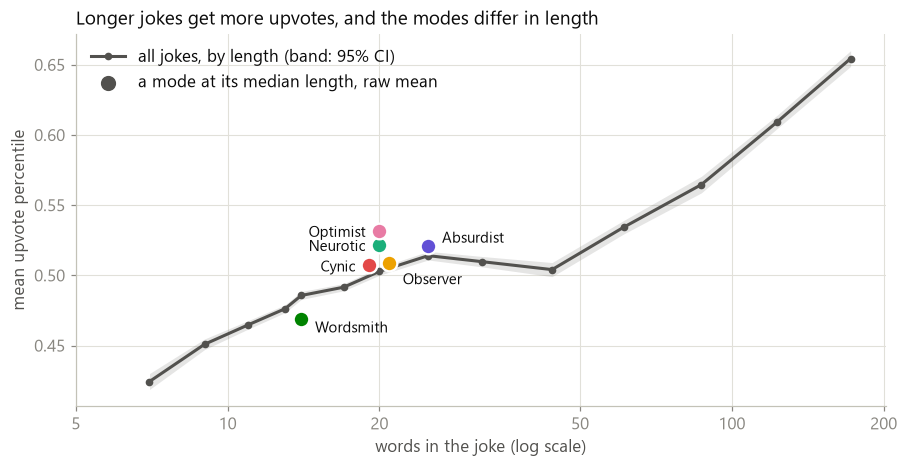

✅ **Slide `30-the-length-confound` matches the metrics (4 values, within ±0.01)**

✅ **Prep caps jokes at 200 words, so the slide's 101-to-300 bin really ends at 200**

✅ **Length spans more than the raw mode spread (0.23 vs 0.06)**

np.True_

In [10]:
def length_curve(jokes, edges, slide_bins):
    # The slide's bins came from a one-off check, so this keeps the numbers in the cache.
    w, p = [], []
    with open(jokes, encoding="utf-8") as f:
        for line in f:
            r = json.loads(line)
            w.append(r["n_words"]); p.append(r["pct"])
    w, p = np.array(w), np.array(p, dtype=float)
    def stats(lo, hi):
        m = (w >= lo) & (w <= hi)
        return {"lo": lo, "hi": hi, "n": int(m.sum()), "median_words": float(np.median(w[m])), "mean_pct": float(p[m].mean()),
                "halfwidth": float(1.96 * p[m].std() / np.sqrt(m.sum()))}
    return {"jokes": len(w), "max_words": int(w.max()), "bins": [stats(a, b) for a, b in edges], "slide_bins": [stats(a, b) for a, b in slide_bins]}

edges = [[4, 7], [8, 9], [10, 11], [12, 13], [14, 15], [16, 18], [19, 22], [23, 28], [29, 38], [39, 50], [51, 75], [76, 100], [101, 150], [151, 200]]
slide_bins = [[0, 13], [19, 50], [51, 100], [101, 300]]
lc = run_or_load("length_curve", length_curve, jokes="data/processed/rjokes/train.jsonl", edges=edges, slide_bins=slide_bins)

x = np.array([s["median_words"] for s in lc["bins"]])
y = np.array([s["mean_pct"] for s in lc["bins"]])
h = np.array([s["halfwidth"] for s in lc["bins"]])
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.fill_between(x, y - h, y + h, color=SLATE, alpha=.15, lw=0)
ax.plot(x, y, color=SLATE, marker="o", ms=4, label="all jokes, by length (band: 95% CI)")
offs = {"neurotic": (-9, -4), "absurdist": (9, 2), "cynic": (-9, -4), "observer": (9, -14), "optimist": (-9, -4), "wordsmith": (9, -9)}
nudge = {"cynic": .955, "observer": 1.045}  # same median and nearly the same mean, so one would hide the other
for m, words, raw in zip(modes, rank["median_words"], rank["raw_mean_pct"]):
    words *= nudge.get(m, 1)
    ax.scatter(words, raw, s=105, color=MODE[m], zorder=4, edgecolor=PAPER, lw=1.5)
    ax.annotate(m.capitalize(), (words, raw), xytext=offs[m], textcoords="offset points", ha="left" if offs[m][0] > 0 else "right", fontsize=9.5)
ax.scatter([], [], s=80, color=SLATE, label="a mode at its median length, raw mean")
ax.set_xscale("log"); ax.set_xticks([5, 10, 20, 50, 100, 200], ["5", "10", "20", "50", "100", "200"]); ax.minorticks_off()
ax.set_xlabel("words in the joke (log scale)"); ax.set_ylabel("mean upvote percentile"); ax.legend(loc="upper left")
ax.set_title("Longer jokes get more upvotes, and the modes differ in length")
done(fig, "30-length-confound")

typed = list(slide("30-the-length-confound").items())
check_slide("30-the-length-confound", {k: s["mean_pct"] for (k, _), s in zip(typed, lc["slide_bins"])}, 0.01)
check(f"Prep caps jokes at {lc['max_words']} words, so the slide's 101-to-300 bin really ends at 200", lc["max_words"] == 200)
spread = max(rank["raw_mean_pct"]) - min(rank["raw_mean_pct"])
check(f"Length spans more than the raw mode spread ({y.max() - y.min():.2f} vs {spread:.2f})", y.max() - y.min() > spread)

**What it decided.** Modes are compared only against jokes of the same year and similar length. Wordsmith's low raw score
is partly its short jokes, while optimist and neurotic sit above the curve, which is where mode itself may matter. Length
explains little about any one joke (Spearman ρ +0.13), and this doesn't show that length *causes* upvotes, but the mode
effects are smaller still: across length quartiles `pct` moves 0.085, against about 0.04 for mode, and absurdist falls from
third to fifth with length deciles. The deck says 101 to 300 words and a median absurdist joke of 26; the data say 200
and 25.

## 9. Do people agree with the judge? (slide 31)

**Context.** The judge's win rates against a *win rate vs the field* from upvotes, in the same unit, on 89,200 jokes. A joke competes only with similar-length jokes from the same
year, split into length deciles.

**Why a slope chart, then a zoom.** On a shared scale, the slopes show two things at once: how much flatter people are,
and where the lines cross. But that flatness tempts you to say people don't care about mode, and the scale can't show
which differences are real. So the right panel zooms in, with CIs and a second binning.

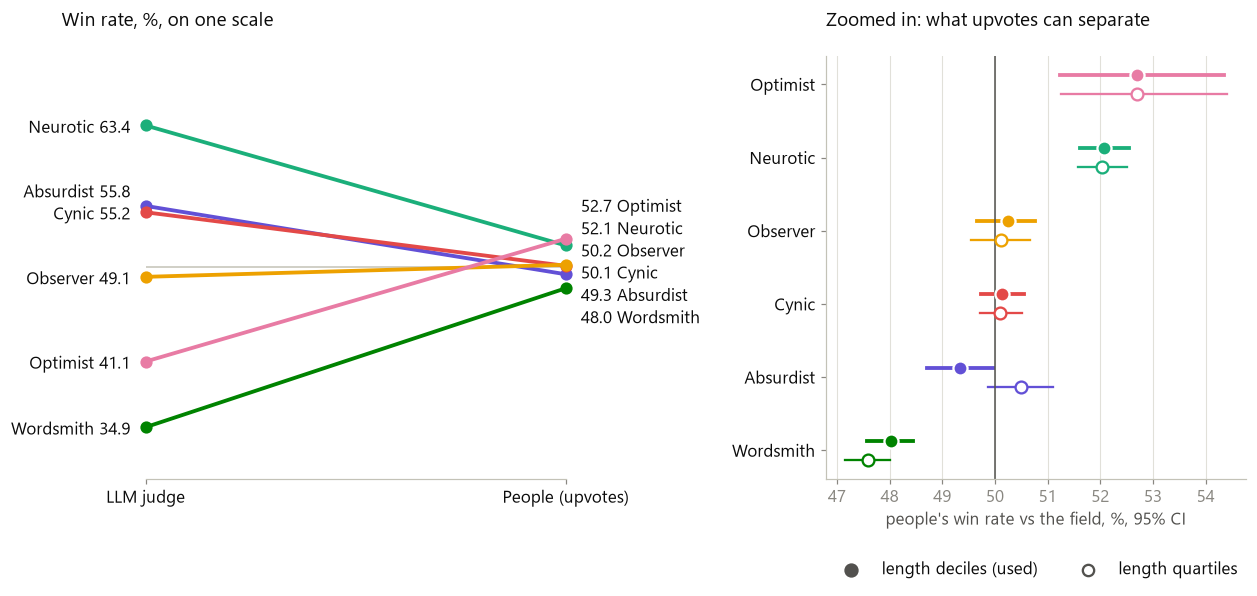

✅ **Slide `31-people-vs-the-llm-judge-1` matches the metrics (6 values, within ±0.05)**

✅ **Slide `31-people-vs-the-llm-judge-2` matches the metrics (6 values, within ±0.05)**

✅ **Spearman ρ runs from +0.20 to +0.37, agreement but weak**

✅ **People clearly disagree on optimist: judge below 50%, people's CI above it**

✅ **Wordsmith is last for both**

True

In [11]:
d10, q4 = rank["variants"]["WR-d10"], rank["variants"]["WR-q4"]
people = dict(zip(modes, np.array(d10["estimate"]) * 100))

fig, (a, b) = plt.subplots(1, 2, figsize=(12.2, 5), gridspec_kw={"width_ratios": [1, 1]})
left = dodge([judge[m] for m in modes], 2.1); right = dodge([people[m] for m in modes], 2.1)
for m, ly, ry in zip(modes, left, right):
    a.plot([0, 1], [judge[m], people[m]], color=MODE[m], lw=2.5, marker="o", ms=7, clip_on=False, zorder=3)
    a.annotate(f"{m.capitalize()} {judge[m]:.1f}", (0, ly), xytext=(-10, 0), textcoords="offset points", ha="right", va="center", annotation_clip=False)
    a.annotate(f"{people[m]:.1f} {m.capitalize()}", (1, ry), xytext=(10, 0), textcoords="offset points", va="center", annotation_clip=False)
a.axhline(50, color=BASE, lw=1)
a.set_xlim(0, 1); a.set_ylim(30, 70); a.set_xticks([0, 1], ["LLM judge", "People (upvotes)"], color=INK, fontsize=11)
a.set_yticks([]); a.grid(False); a.spines["left"].set_visible(False)
a.set_title("Win rate, %, on one scale\n", x=-.2)

order = sorted(modes, key=lambda m: people[m])
for y, m in enumerate(order):
    i = modes.index(m)
    (lo_d, hi_d), (lo_q, hi_q) = (d10["ci"][0][i] * 100, d10["ci"][1][i] * 100), (q4["ci"][0][i] * 100, q4["ci"][1][i] * 100)
    b.plot([lo_d, hi_d], [y + .13, y + .13], color=MODE[m], lw=2.5)
    b.scatter(people[m], y + .13, s=85, color=MODE[m], zorder=3, edgecolor=PAPER, lw=1.5)
    b.plot([lo_q, hi_q], [y - .13, y - .13], color=MODE[m], lw=1.5)
    b.scatter(q4["estimate"][i] * 100, y - .13, s=60, color=PAPER, edgecolor=MODE[m], lw=1.5, zorder=3)
b.axvline(50, color=SLATE, lw=1)
b.set_yticks(range(6), [m.capitalize() for m in order], color=INK); b.grid(axis="y", visible=False)
b.set_xlabel("people's win rate vs the field, %, 95% CI")
b.scatter([], [], s=70, color=SLATE, label="length deciles (used)"); b.scatter([], [], s=55, color=PAPER, edgecolor=SLATE, lw=1.5, label="length quartiles")
b.legend(loc="lower center", bbox_to_anchor=(.5, -.27), ncol=2)
b.set_title("Zoomed in: what upvotes can separate\n")
fig.subplots_adjust(wspace=.62, left=.16, right=.98)
done(fig, "31-people-vs-judge")

short = {m[:3].capitalize(): v for m, v in people.items()}
check_slide("31-people-vs-the-llm-judge-1", {m[:3].capitalize(): v for m, v in judge.items()}, 0.05)
check_slide("31-people-vs-the-llm-judge-2", short, 0.05)
rhos = [v["rho"] for v in rank["variants"].values()]
check(f"Spearman ρ runs from {min(rhos):+.2f} to {max(rhos):+.2f}, agreement but weak", min(rhos) == .2 and max(rhos) < .4)
check("People clearly disagree on optimist: judge below 50%, people's CI above it", judge["optimist"] < 50 and d10["ci"][0][modes.index("optimist")] > .5)
check("Wordsmith is last for both", min(judge, key=judge.get) == "wordsmith" == min(people, key=people.get))

**What it shows.** They agree on neurotic above average and wordsmith last, and they clearly disagree on optimist. The
order of the middle modes can't be settled: absurdist, cynic and observer shift with the binning, and absurdist moves
across the 50% line.

**Don't overread the flat line.** Upvotes are noisy, these jokes were labelled afterward rather than written per mode, and
about 8% of labels are wrong. All of that pulls win rates towards 50%, so flat here doesn't mean people care less about
mode. It also means the human taste below is an estimate, not a measurement of a live room.

## 10. So does the director choice survive? (slide 33)

**Context.** The sim's `base` taste came from the judge, so we re-ran the policy comparison with `base` taken from the
decile win rates. Criteria were fixed before running.

**Why a strip and connected dots.** The strip shows what actually changed in the sim, the input: the spread between modes
collapses. The connected dots show the output on one axis, for every policy and every fixed mode, with each in its
usual colour. A hollow dot is the judge's taste and a filled one is the human taste.

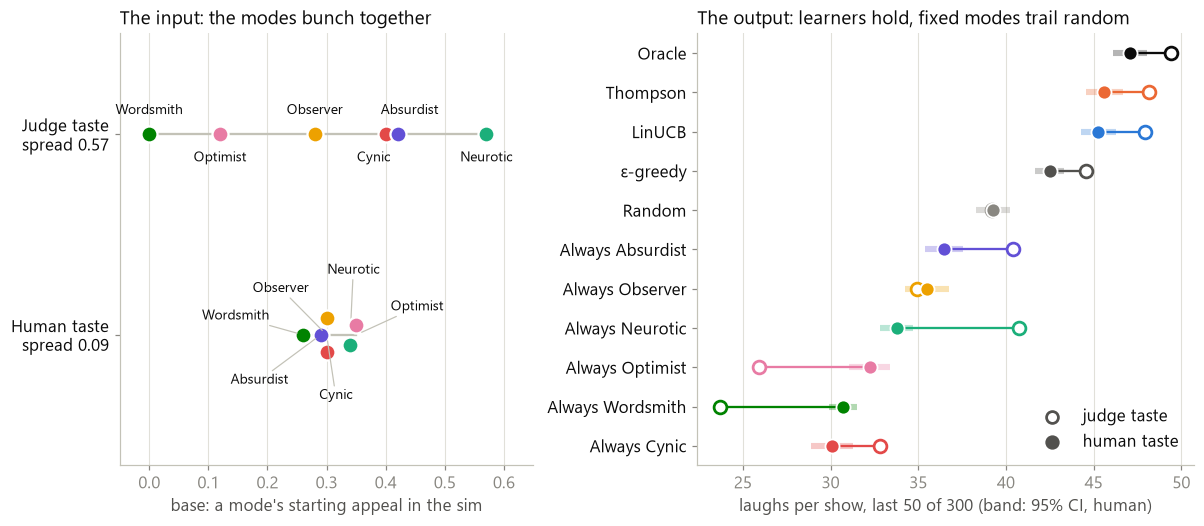

✅ **Slide `33-two-tastes` matches the metrics (6 values, within ±0.05)**

✅ **LinUCB reaches 96.2% of the oracle under human taste (at least 95%)**

✅ **Random beats every fixed mode under human taste, which it doesn't under the judge's**

✅ **Spread falls from 0.57 to 0.09**

True

In [12]:
tt = metric("two_tastes")
J, H = tt["tastes"]["judge"], tt["tastes"]["human"]

fig, (a, b) = plt.subplots(1, 2, figsize=(12.6, 5.1), gridspec_kw={"width_ratios": [1, 1.2]})
stagger = {"neurotic": (2, 40), "optimist": (40, 16), "absurdist": (-40, -32), "cynic": (6, -42), "observer": (-30, 28), "wordsmith": (-44, 10)}
judge_off = {"wordsmith": (0, 13), "optimist": (0, -18), "observer": (0, 13), "cynic": (-8, -18), "absurdist": (8, 13), "neurotic": (0, -18)}
tie = {"cynic": -.085, "observer": .085, "neurotic": -.05, "optimist": .05, "absurdist": 0, "wordsmith": 0}  # exact ties would hide a dot
for y, (taste, vals) in ((1, ("judge", tt["base"]["judge"])), (0, ("human", tt["base"]["human"]))):
    a.plot([min(vals.values()), max(vals.values())], [y, y], color=BASE, lw=1.5, zorder=1)
    for i, (m, v) in enumerate(vals.items()):
        a.scatter(v, y + (tie[m] if taste == "human" else 0), s=110, color=MODE[m], edgecolor=PAPER, lw=1.5, zorder=3)
        off = judge_off[m] if taste == "judge" else stagger[m]
        a.annotate(m.capitalize(), (v, y), xytext=off, textcoords="offset points", ha="center", fontsize=9,
                   arrowprops=dict(arrowstyle="-", color=BASE, lw=.8, shrinkA=0, shrinkB=4) if taste == "human" else None)
spread = {k: max(v.values()) - min(v.values()) for k, v in tt["base"].items()}
a.set_yticks([1, 0], [f"Judge taste\nspread {spread['judge']:.2f}", f"Human taste\nspread {spread['human']:.2f}"], color=INK)
a.set_xlim(-.05, .65); a.set_ylim(-.65, 1.5); a.grid(axis="y", visible=False); a.set_xlabel("base: a mode's starting appeal in the sim")
a.set_title("The input: the modes bunch together")

rows = [("Oracle", "oracle", INK), ("Thompson", "Thompson (LinTS) | uniform", LINE["Thompson"][0]), ("LinUCB", "LinUCB | uniform", LINE["LinUCB"][0]),
        ("ε-greedy", "ε-greedy | uniform", SLATE), ("Random", "random", MUTED)]
fixed = sorted(MODE, key=lambda m: -H["rows"][f"fixed {m}"]["warm"][0])
rows += [(f"Always {m.capitalize()}", f"fixed {m}", MODE[m]) for m in fixed]
for y, (name, key, col) in enumerate(reversed(rows)):
    (jm, jh), (hm, hh) = J["rows"][key]["warm"], H["rows"][key]["warm"]
    b.plot([jm, hm], [y, y], color=col, lw=1.5, zorder=1)
    b.plot([hm - hh, hm + hh], [y, y], color=col, lw=4, alpha=.3, solid_capstyle="butt", zorder=1)
    b.scatter(jm, y, s=70, color=PAPER, edgecolor=col, lw=1.8, zorder=3)
    b.scatter(hm, y, s=85, color=col, edgecolor=PAPER, lw=1.2, zorder=3)
b.set_yticks(range(len(rows)), [r[0] for r in reversed(rows)], color=INK); b.grid(axis="y", visible=False)
b.set_xlabel("laughs per show, last 50 of 300 (band: 95% CI, human)")
b.scatter([], [], s=60, color=PAPER, edgecolor=SLATE, lw=1.8, label="judge taste"); b.scatter([], [], s=70, color=SLATE, label="human taste")
b.legend(loc="lower right")
b.set_title("The output: learners hold, fixed modes trail random")
fig.subplots_adjust(wspace=.36)
done(fig, "33-two-tastes")

hr = H["rows"]; hc2 = H["criteria"]
check_slide("33-two-tastes", {"Oracle": hr["oracle"]["warm"][0], "Thompson": hr["Thompson (LinTS) | uniform"]["warm"][0], "LinUCB": hr["LinUCB | uniform"]["warm"][0],
                               "ε-greedy": hr["ε-greedy | uniform"]["warm"][0], "Random": hr["random"]["warm"][0], "Best fixed": hr[hc2["best_fixed"]]["warm"][0]}, 0.05)
check(f"LinUCB reaches {hc2['share_of_oracle']:.1%} of the oracle under human taste (at least 95%)", hc2["p1"])
check(f"Random beats every fixed mode under human taste, which it doesn't under the judge's",
      all(hr["random"]["warm"][0] > hr[f"fixed {m}"]["warm"][0] for m in MODE)
      and not all(J["rows"]["random"]["warm"][0] > J["rows"][f"fixed {m}"]["warm"][0] for m in MODE))
check(f"Spread falls from {spread['judge']:.2f} to {spread['human']:.2f}", round(spread["judge"], 2) == .57 and round(spread["human"], 2) == .09)

**What it decided.** The director choice holds: LinUCB with a uniform prior gets 96.2% of the oracle and stays clearly above
the best fixed mode. Thompson isn't clearly better (its CI overlaps), so there's no reason to switch.

**What it doesn't show.** Only `base` changed. The venue and age offsets are still made up, so this shows the choice
doesn't depend on the base taste, not how much learning would help in a real room. Random beating every fixed mode is
probably because no mode has much of a head start, but we didn't test that. **Real logged sessions outrank all of it.**

## 11. Is the oracle really the ceiling? (Exp 16; Q&A notes on slides 15 and 17)

**Context.** Every result so far is a share of the oracle, and we called it the ceiling. But the oracle picks the best *next*
bit, so it can't plan around fatigue. An exact best sequence for each room gives the true ceiling.

**Why a forest plot and sorted dots.** The left panel puts the three policies on one axis under both tastes, with their CIs.
Those CIs are across careers and aren't paired, so overlap there doesn't settle the gap. The right panel does: it's exact, with
no sampling, and shows the gap in each of the 27 rooms, largest first. A hollow dot is the judge's taste and a filled one is the
human taste, as in the chart above.


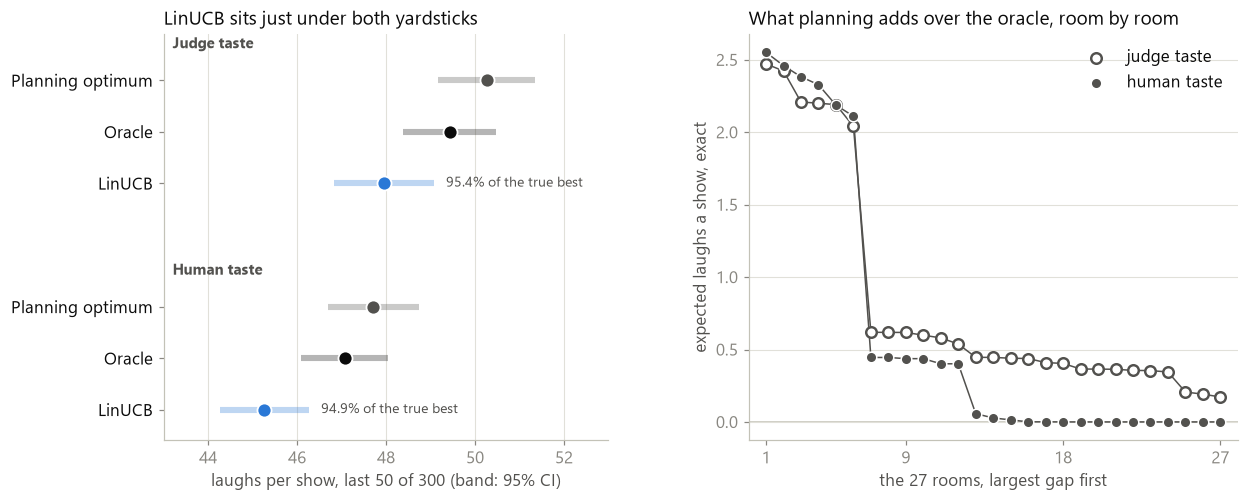

✅ **LinUCB is 97.0% of the oracle and 95.4% of the true best under judge taste**

✅ **Planning never loses to the oracle, and beats it in 27 of 27 rooms under judge taste and 17 under human taste**

✅ **The gap is small: 0.83 laughs a show on average under judge taste, at most 2.47**

np.True_

In [13]:
po = metric("planning_optimum")
rows = [("planning optimum", "Planning optimum", SLATE), ("oracle", "Oracle", INK), ("LinUCB | uniform", "LinUCB", LINE["LinUCB"][0])]

fig, (a, b) = plt.subplots(1, 2, figsize=(12.6, 4.8), gridspec_kw={"width_ratios": [1, 1.1]})
ticks, labels = [], []
for base, (taste, title) in ((4.4, ("judge", "Judge taste")), (0, ("human", "Human taste"))):
    for k, (key, name, col) in enumerate(rows):
        y = base + 2 - k
        m, h = po[taste]["rows"][key]["warm"]
        a.plot([m - h, m + h], [y, y], color=col, lw=4, alpha=.3, solid_capstyle="butt", zorder=1)
        a.scatter(m, y, s=85, color=col, edgecolor=PAPER, lw=1.2, zorder=3)
        ticks.append(y); labels.append(name)
    a.text(43.2, base + 2.62, title, fontsize=10, color=SLATE, fontweight="bold")
    m, h = po[taste]["rows"]["LinUCB | uniform"]["warm"]
    a.annotate(f"{po[taste]['chosen_of_planning']:.1%} of the true best", (m + h, base), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=SLATE)
a.set_yticks(ticks, labels, color=INK); a.grid(axis="y", visible=False)
a.set_xlim(43, 53); a.set_ylim(-.6, 7.3); a.set_xlabel("laughs per show, last 50 of 300 (band: 95% CI)")
a.set_title("LinUCB sits just under both yardsticks")

gap = {t: sorted((r["planning"] - r["oracle"] for r in po[t]["rooms"]), reverse=True) for t in ("judge", "human")}
x = np.arange(1, 28)
b.axhline(0, color=BASE, lw=1, zorder=0)
b.plot(x, gap["judge"], color=SLATE, lw=1, zorder=1); b.plot(x, gap["human"], color=SLATE, lw=1, zorder=1)
b.scatter(x, gap["judge"], s=48, color=PAPER, edgecolor=SLATE, lw=1.6, zorder=3, label="judge taste")
b.scatter(x, gap["human"], s=48, color=SLATE, edgecolor=PAPER, lw=1, zorder=3, label="human taste")
b.set_xlim(0, 28); b.set_xticks([1, 9, 18, 27]); b.grid(axis="x", visible=False); b.legend(loc="upper right")
b.set_xlabel("the 27 rooms, largest gap first"); b.set_ylabel("expected laughs a show, exact")
b.set_title("What planning adds over the oracle, room by room")
fig.subplots_adjust(wspace=.3)
done(fig, "exp16-planning-optimum")

jg, hg = np.array(gap["judge"]), np.array(gap["human"])
check(f"LinUCB is {po['judge']['chosen_of_oracle']:.1%} of the oracle and {po['judge']['chosen_of_planning']:.1%} of the true best under judge taste",
      round(po["judge"]["chosen_of_oracle"], 3) == .970 and round(po["judge"]["chosen_of_planning"], 3) == .954)
check(f"Planning never loses to the oracle, and beats it in {po['judge']['rooms_planning_wins']} of 27 rooms under judge taste and {po['human']['rooms_planning_wins']} under human taste",
      jg.min() > -1e-9 and hg.min() > -1e-9 and po["judge"]["rooms_planning_wins"] == 27 and po["human"]["rooms_planning_wins"] == 17)
check(f"The gap is small: {jg.mean():.2f} laughs a show on average under judge taste, at most {jg.max():.2f}", round(jg.mean(), 2) == .83 and round(jg.max(), 2) == 2.47)


**What it shows.** The average hides a cliff. Under each taste, 6 of the 27 rooms gain over 2 laughs a show from planning and the other 21 gain about 0.6 or less. The 6 aren't the same rooms: under judge taste they're the teen rooms at bars and showcases, and under human taste the young-adult rooms at bars and the teen rooms at showcases. No company event is among them. We didn't test why.

**What it decided.** Keep the oracle as the yardstick and report the true ceiling beside it, since the order of the policies
doesn't change. Say "97% of the oracle, about 95% of the true best".

**What it doesn't show.** This covers steady shows only: the shift experiments still compare against the oracle. No bar was
fixed beforehand, and the fatigue being planned around is made up.


## 12. What does exploring cost? (Exp 18)

**Context.** The live director explores at ε = 0.2 so its logs carry exact pick probabilities. Each pick has a one in five chance of being
random, so some laughs are given up. The bar, fixed before running, was at most 1 laugh per show at 5 shows, at the far end of the CI,
in every room.

**Why a forest plot.** The bar is a line on one axis, and what matters is which side of it each CI's far end falls on. Rows are the six
rooms (judge and human taste, with the gaps between modes halved, as they are and doubled). Each change is paired on seeds against ε = 0.

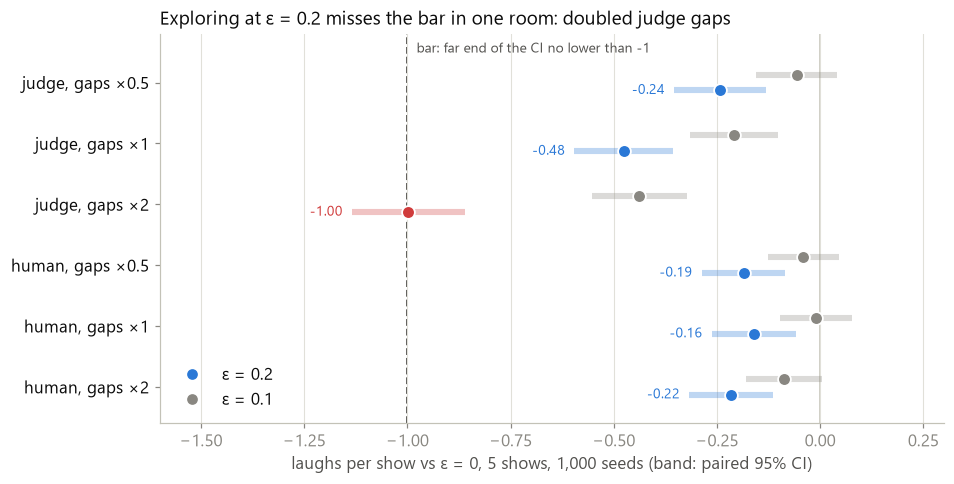

✅ **Five of six rooms meet the bar; judge, gaps x2 misses with its far end at -1.13**

✅ **Every other room's far end is above -0.7, so the miss is the doubled judge gaps alone**

True

In [14]:
ec = metric("epsilon_cost")
names = list(ec["variants"])
fig, ax = plt.subplots(figsize=(9.2, 4.6))
ticks = []
for k, name in enumerate(names):
    y = len(names) - 1 - k
    for eps, dy, col in (("0.1", .13, MUTED), ("0.2", -.13, LINE["LinUCB"][0])):
        m, h = ec["variants"][name]["5"][eps]["diff"]
        bad = eps == "0.2" and not ec["criteria"]["variants"][name]["pass"]
        c = MISSED if bad else col
        ax.plot([m - h, m + h], [y + dy] * 2, color=c, lw=4, alpha=.3, solid_capstyle="butt", zorder=1)
        ax.scatter(m, y + dy, s=70, color=c, edgecolor=PAPER, lw=1.2, zorder=3)
        if eps == "0.2":
            ax.annotate(f"{m:+.2f}", (m - h, y + dy), xytext=(-6, 0), textcoords="offset points", ha="right", va="center", fontsize=9, color=c)
    ticks.append((y, name.replace(" x", " ×")))
ax.axvline(-1, color=SLATE, lw=1.2, ls="--", zorder=0)
ax.annotate("bar: far end of the CI no lower than -1", (-1, len(names) - .45), xytext=(6, 0), textcoords="offset points", fontsize=9, color=SLATE, va="center")
ax.axvline(0, color=BASE, lw=1, zorder=0)
ax.set_yticks([t[0] for t in ticks], [t[1] for t in ticks], color=INK)
ax.grid(axis="y", visible=False)
ax.set_xlim(-1.6, .3); ax.set_ylim(-.6, len(names) - .2)
ax.set_xlabel("laughs per show vs ε = 0, 5 shows, 1,000 seeds (band: paired 95% CI)")
ax.set_title("Exploring at ε = 0.2 misses the bar in one room: doubled judge gaps")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=LINE["LinUCB"][0], label="ε = 0.2"), plt.Line2D([], [], marker="o", ls="", color=MUTED, label="ε = 0.1")], loc="lower left")
done(fig, "exp18-epsilon-cost")

miss = [n for n, c in ec["criteria"]["variants"].items() if not c["pass"]]
check(f"Five of six rooms meet the bar; {miss[0]} misses with its far end at {ec['criteria']['variants'][miss[0]]['far_end']:+.2f}",
      miss == ["judge, gaps x2"] and round(ec["criteria"]["variants"][miss[0]]["far_end"], 2) == -1.13)
check("Every other room's far end is above -0.7, so the miss is the doubled judge gaps alone",
      all(c["far_end"] > -0.7 for n, c in ec["criteria"]["variants"].items() if n not in miss))

**What it shows.** The cost sits between 0 and 0.5 laughs a show in five rooms and reaches 1.00 (far end 1.13) when the judge's gaps between
modes are doubled, which makes a wrong pick expensive. Human taste costs 0.16 to 0.22 whatever the gaps, because its modes are close together.

**What it decided.** Nothing yet: the miss goes to the user (decisions.md, Exp 18 entry).

**What it doesn't show.** The 30-show rows (in the table in decisions-director.ipynb) had no bar. The sim's mode gaps are made up apart from where
`base` comes from.

## Does every decision have a chart?

Each experiment in the `decisions-*.ipynb` notebooks (indexed in [decisions.ipynb](decisions.ipynb)) needs an entry here: its figures, or the reason it has none. Figures can
live in this notebook's folder or in `reports/figures/`. A new experiment without an entry fails this check.


In [15]:
DP = "reports/figures/decision-plot"
COVERAGE = {
    1: "No chart: one F1 score against a baseline, and a table says it.",
    2: "No chart: a data-cleaning step, with nothing to compare.",
    3: [f"{DP}/15-best-mode-by-room.png", f"{DP}/16-per-joke-vs-per-bit.png"],
    4: [f"{DP}/18-laughs-lost.png", "reports/figures/laughs_lost_across_shows.png"],
    5: [f"{DP}/20-when-the-room-turns.png"],
    6: ["reports/figures/shift_recovery_by_set_length.png"],
    7: ["reports/figures/show_state_a.png"],
    8: ["reports/figures/show_state_b.png"],
    9: [f"{DP}/29-hand-check.png"],
    10: [f"{DP}/30-length-confound.png", f"{DP}/31-people-vs-judge.png"],
    11: "No chart: one CI per mode against a fixed rule, and a table says it.",
    12: ["reports/figures/rjokes_correlations.png"],
    13: [f"{DP}/33-two-tastes.png"],
    14: [f"{DP}/25-step-c-planning.png"],
    15: [f"{DP}/25-step-c-planning.png"],
    16: [f"{DP}/exp16-planning-optimum.png"],
    18: [f"{DP}/exp18-epsilon-cost.png"],
}
exps = {int(m.group(1)) for path in sorted((ROOT / "notebooks").glob("decisions-*.ipynb"))
        for c in json.loads(path.read_text(encoding="utf-8"))["cells"] if c["cell_type"] == "markdown"
        for m in [re.match(r"##\s*Exp (\d+)", "".join(c["source"]))] if m}
missing = sorted(exps - COVERAGE.keys())
stale = sorted(COVERAGE.keys() - exps)
absent = [p for v in COVERAGE.values() if isinstance(v, list) for p in v if not (ROOT / p).exists()]
charted = sum(isinstance(COVERAGE[e], list) for e in exps & COVERAGE.keys())
check(f"All {len(exps)} experiments have a chart ({charted}) or a stated reason ({len(exps) - charted})"
      + (f"; missing: {missing}" if missing else "") + (f"; no longer in the decisions notebooks: {stale}" if stale else "")
      + (f"; files not found: {absent}" if absent else ""), not missing and not stale and not absent)


✅ **All 17 experiments have a chart (14) or a stated reason (3)**

True

## Where each chart leaves the deck

Slides 14, 18, 20, 29, 30, 31 and 33 now use the PNGs in `reports/figures/decision-plot/`. The other figures (15, 16, 25 and
the Exp 16 chart) are not in `humor-me.pptx`, because those slides are still flowcharts. The old `.mmd` files stay beside the deck as the record
of the numbers it first showed, and the checks above compare against them.

The old slide 30 chart had two problems, both fixed by this redraw: its last bin was labelled 101 to 300 words although prep
caps jokes at 200, and its bins skipped 14 to 18 words. The other items in the "Still yours to decide" table in
[slides.md](../docs/slides/slides.md) are unchanged.

**After changing a chart here**, re-run `python scripts/run_notebook.py notebooks/decision-plot.ipynb`, then copy the PNG
into the deck again.